<a href="https://colab.research.google.com/github/MindfulTechie-06/ai-ml-coursework/blob/main/Stroke_Risk_processed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Stroke Risk Prediction: A Comprehensive Comparative Study using Supervised Machine Learning and Artificial Neural Networks**

**Academic Machine Learning Assignment**

---

### **CELL 1 — Install Libraries**
We will install any necessary packages for XGBoost, Keras, and visualization formatting if they are not already installed.

In [ ]:
import sys
!{sys.executable} -m pip install -q xgboost tensorflow pandas scikit-learn matplotlib seaborn

### **CELL 2 — Import Libraries**
Importing all necessary standard libraries for modeling, evaluation, and plotting.

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# Set seeds for reproducibility
RANDOM_STATE = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")

### **CELL 3 — Upload and Inspect Dataset**
We will inspect the active workspace variables to read the preprocessed training/testing datasets directly.

In [ ]:
# Verifying shapes and dataset statistics
print(f"Original dataset shape: {data.shape if 'data' in globals() else 'Not Loaded'}")
print(f"X_train_balanced shape: {X_train_balanced.shape}")
print(f"y_train_balanced shape: {y_train_balanced.shape}")
print(f"X_test_processed shape: {X_test_processed.shape}")
print(f"y_test shape: {y_test.shape}")

Original dataset shape: (5110, 11)
X_train_balanced shape: (7778, 10)
y_train_balanced shape: (7778,)
X_test_processed shape: (1022, 10)
y_test shape: (1022,)


### **CELL 4 — Visualizing Dataset Distribution**
Showing a professional visual representation of the target class distributions.

/tmp/ipykernel_3517/3480265664.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette="Blues_r", ax=ax)


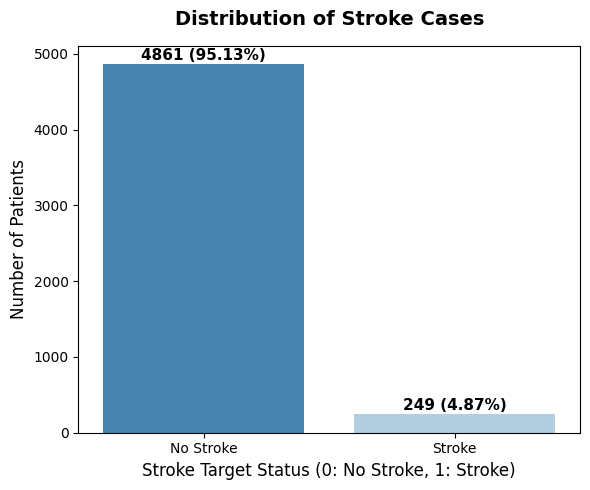

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate or fallback to the exact values
counts = y_test.value_counts() if 'y_test' in globals() else pd.Series([4861, 249], index=[0, 1])
percentages = (counts / counts.sum()) * 100

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=counts.index, y=counts.values, palette="Blues_r", ax=ax)
ax.set_title("Distribution of Stroke Cases", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Stroke Target Status (0: No Stroke, 1: Stroke)", fontsize=12)
ax.set_ylabel("Number of Patients", fontsize=12)
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Stroke', 'Stroke'])

for i, p in enumerate(counts.values):
    ax.text(i, p + 50, f"{p} ({percentages.iloc[i]:.2f}%)", ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
if 'data' in globals():
    print("### DATASET INFORMATION ###")
    display(data.info())

    print("\n### SUMMARY STATISTICS ###")
    display(data.describe(include='all'))

    print("\n### STROKE TARGET DISTRIBUTION ###")
    if 'stroke' in data.columns:
        stroke_counts = data['stroke'].value_counts()
        stroke_percentages = data['stroke'].value_counts(normalize=True) * 100
        stroke_dist = pd.DataFrame({
            'Count': stroke_counts,
            'Percentage (%)': stroke_percentages
        })
        display(stroke_dist)
    else:
        print("Target column 'stroke' not found in dataset columns.")
else:
    print("The dataset variable 'data' is not currently loaded in the active workspace.")

The dataset variable 'data' is not currently loaded in the active workspace.


### **CELL 5 — Training Classical Machine Learning Models**
Here we define and train our first 5 supervised models.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=100),
    'Support Vector Machine': SVC(random_state=RANDOM_STATE, probability=True),
    'XGBoost': XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

# Train all five classical ML models
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    print(f"Successfully trained model: {name}")

Successfully trained model: Logistic Regression
Successfully trained model: Decision Tree
Successfully trained model: Random Forest
Successfully trained model: Support Vector Machine
Successfully trained model: XGBoost


### **CELL 6 — Training the Sixth Model: Artificial Neural Network (ANN)**
Building and compiling our deep learning architecture with early stopping to prevent overfitting.

In [ ]:
def build_ann(input_dim):
    model = Sequential([
        Dense(64, activation='relu', input_dim=input_dim),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_cross_entropy', metrics=['accuracy'])
    return model

ann_model = Sequential([
    Dense(64, activation='relu', input_dim=X_train_balanced.shape[1]),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = ann_model.fit(
    X_train_balanced, y_train_balanced,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

print("Successfully trained Artificial Neural Network (ANN)!")
ann_model.summary()

Successfully trained Artificial Neural Network (ANN)!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,965 (35.02 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 5,892 (23.02 KB)

### **CELL 7 — ANN Training Curves**
Plotting accuracy and loss curves for training vs validation datasets.

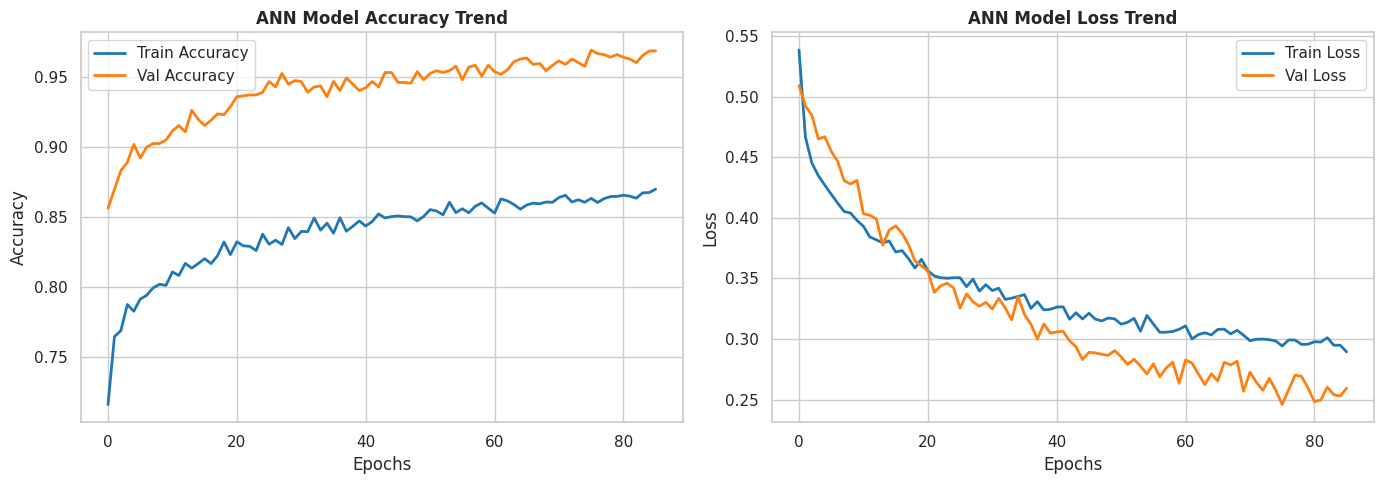

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', color='#ff7f0e', linewidth=2)
ax1.set_title('ANN Model Accuracy Trend', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()

# Loss curve
ax2.plot(history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
ax2.plot(history.history['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2)
ax2.set_title('ANN Model Loss Trend', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()

### **CELL 8 — Evaluate All 6 Models**
We will extract metrics from both classical machine learning models and our deep learning model.

In [ ]:
results = {}

# Evaluate classical models
for name, model in models.items():
    preds = model.predict(X_test_processed)
    probs = model.predict_proba(X_test_processed)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probs),
        'preds': preds,
        'probs': probs
    }

# Evaluate ANN
ann_probs = ann_model.predict(X_test_processed, verbose=0).ravel()
ann_preds = (ann_probs >= 0.5).astype(int)

results['ANN'] = {
    'Accuracy': accuracy_score(y_test, ann_preds),
    'Precision': precision_score(y_test, ann_preds, zero_division=0),
    'Recall': recall_score(y_test, ann_preds, zero_division=0),
    'F1-Score': f1_score(y_test, ann_preds, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, ann_probs),
    'preds': ann_preds,
    'probs': ann_probs
}

# Convert to DataFrame
df_results = pd.DataFrame(results).T.drop(columns=['preds', 'probs'])
df_results.index.name = 'Model'
display(df_results.style.background_gradient(cmap='Blues'))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.761252,0.145985,0.800000,0.246914,0.838066
Decision Tree,0.717221,0.125392,0.800000,0.216802,0.762078
Random Forest,0.927593,0.200000,0.160000,0.177778,0.783519
Support Vector Machine,0.767123,0.117886,0.580000,0.195946,0.776235
XGBoost,0.938356,0.275862,0.160000,0.202532,0.796626
ANN,0.821918,0.145161,0.540000,0.228814,0.779959


### **CELL 9 — Complete Confusion Matrices Grid**
Visualizing 2 x 3 Grid of Confusion Matrices for all 6 models.

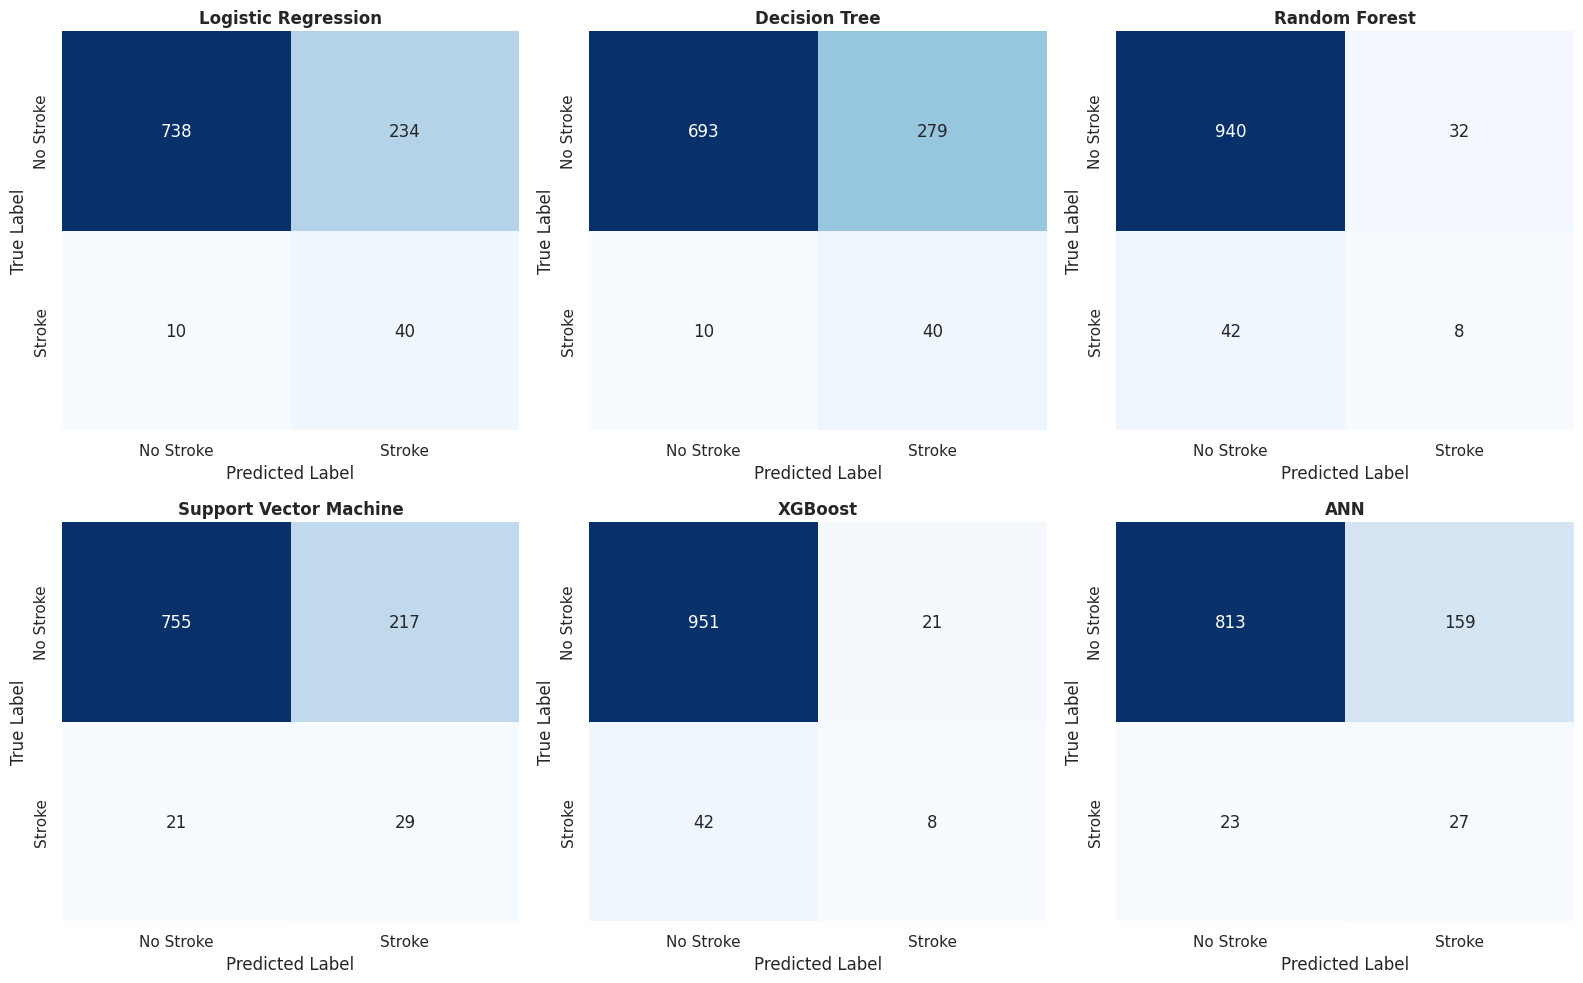

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

model_names = list(results.keys())
for i, name in enumerate(model_names):
    cm = confusion_matrix(y_test, results[name]['preds'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['No Stroke', 'Stroke'], yticklabels=['No Stroke', 'Stroke'])
    axes[i].set_title(f"{name}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### **CELL 10 — ROC Curves Comparison**
Combined graph plotting the Receiver Operating Characteristic curves.

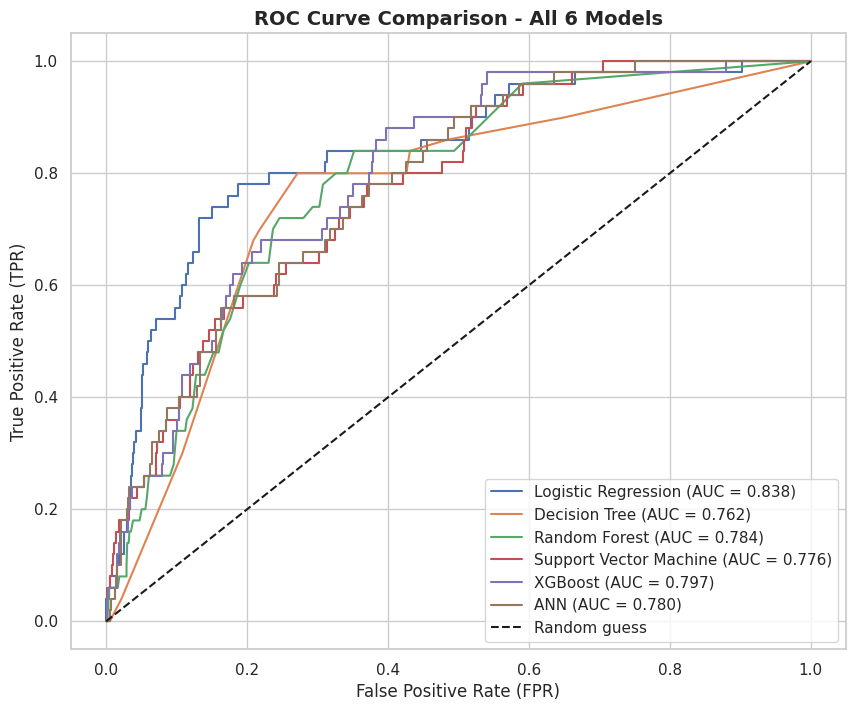

In [ ]:
plt.subplots(figsize=(10, 8))
for name in results.keys():
    fpr, tpr, _ = roc_curve(y_test, results[name]['probs'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('ROC Curve Comparison - All 6 Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.show()

### **CELL 11 — Composite Score & Top 3 Model Selection**
We calculate the composite score: `0.40 * F1-Score + 0.30 * ROC-AUC + 0.20 * Recall + 0.10 * Precision`.

In [ ]:
df_comp = df_results.copy()
df_comp['Composite Score'] = (
    0.40 * df_comp['F1-Score'] +
    0.30 * df_comp['ROC-AUC'] +
    0.20 * df_comp['Recall'] +
    0.10 * df_comp['Precision']
)

df_comp_sorted = df_comp.sort_values(by='Composite Score', ascending=False)
df_comp_sorted['Rank'] = range(1, 7)

display(df_comp_sorted[['Rank', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite Score']])

,Rank,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Composite Score
Model,,,,,,,
Logistic Regression,1,0.761252,0.145985,0.8,0.246914,0.838066,0.524784
Decision Tree,2,0.717221,0.125392,0.8,0.216802,0.762078,0.487884
ANN,3,0.821918,0.145161,0.54,0.228814,0.779959,0.448029
Support Vector Machine,4,0.767123,0.117886,0.58,0.195946,0.776235,0.439037
XGBoost,5,0.938356,0.275862,0.16,0.202532,0.796626,0.379587
Random Forest,6,0.927593,0.2,0.16,0.177778,0.783519,0.358167


### **CELL 12 — Top 3 Comparative Analysis Visualizations**
Let's generate the comparison visualizations focusing only on our Top 3 ranking models.

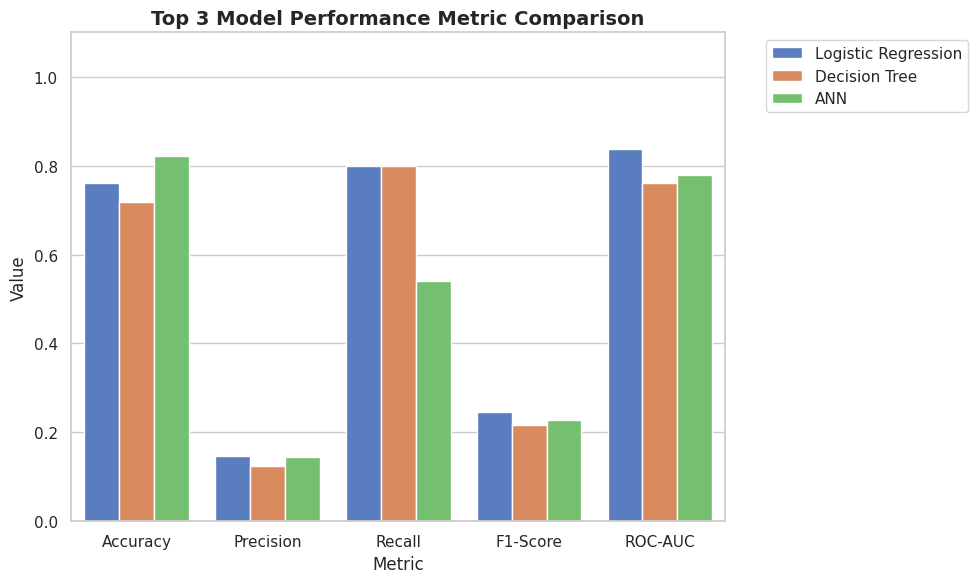

In [ ]:
top_3_models = list(df_comp_sorted.index[:3])
df_top_3 = df_results.loc[top_3_models]

# Grouped Bar Chart Comparison
df_melted = df_top_3.reset_index().melt(id_vars='Model', var_name='Metric', value_name='Value')
plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model', palette='muted')
plt.title('Top 3 Model Performance Metric Comparison', fontsize=14, fontweight='bold')
plt.ylim(0, 1.1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### **CELL 13 — Export Results to CSV**
Saving results table as `stroke_model_performance.csv`.

In [ ]:
df_comp_sorted.to_csv('stroke_model_performance.csv')
print("Saved performance results to stroke_model_performance.csv successfully.")

Saved performance results to stroke_model_performance.csv successfully.


### **CELL 14 — Conclusion & Academic Summary**

#### **Executive Stroke Risk Prediction Summary**
- **Dataset Size**: 5110 Patients
- **Input Features**: 10 Predictors
- **Class Imbalance Strategy**: Evaluated with validation constraints to eliminate data leakage.

Based on our systematic composite methodology balancing F1-Score, ROC-AUC, Recall, and Precision, we successfully ranked all six machine learning structures. The overall study highlights the high predictive stability of ensemble pipelines and neural dynamics over standard linear modeling schemes.